In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/POWER_Regional_Monthly_1984_2025.csv", skiprows=9)

df = df[df["ANN"] != -999].copy()

In [3]:
unique_locations = df[["LAT", "LON"]].drop_duplicates()

unique_locations.to_csv("data/unique_locations.csv", index=False)

In [4]:
df = df.sort_values(["LAT", "LON", "YEAR"]).copy()

df["target_year"] = (
    df.groupby(["LAT", "LON"])["YEAR"].shift(-1)
)

months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
target_cols = [f"next_{month}" for month in months]

for month in months:
    df[f"next_{month}"] = df.groupby(["LAT", "LON"])[month].shift(-1)

df = df[df["target_year"] == df["YEAR"] + 1]
df = df.dropna(subset=target_cols).copy()

In [5]:
features = ["YEAR", "LAT", "LON"]
train = df[df["target_year"] <= 2019]
test = df[df["target_year"] > 2019]

In [6]:
model = LinearRegression()

In [7]:
X_train = train[features]
y_train = train[target_cols]

X_test = test[features]
y_test = test[target_cols]
model.fit(X_train,y_train)
print(model.score(X_train,y_train))

0.16769551701189356


In [8]:
from sklearn.metrics import r2_score

predictions = model.predict(X_test)
actual = np.asarray(y_test)
month_r2 = r2_score(actual, predictions, multioutput="raw_values")
print("Test R²:", month_r2)

for i, month in enumerate(target_cols):
    correlation = np.corrcoef(actual[:, i], predictions[:, i])[0, 1]
    print(f"{month}: R²={month_r2[i]:.3f}, correlation={correlation:.3f}")

Test R²: [ 0.04395615 -0.04020285  0.11982424  0.08817073 -0.01408092 -0.20246966
  0.13152388 -0.16888073  0.11247648 -0.03279018  0.10228289  0.12433962]
next_JAN: R²=0.044, correlation=0.350
next_FEB: R²=-0.040, correlation=0.287
next_MAR: R²=0.120, correlation=0.362
next_APR: R²=0.088, correlation=0.306
next_MAY: R²=-0.014, correlation=0.321
next_JUN: R²=-0.202, correlation=0.403
next_JUL: R²=0.132, correlation=0.384
next_AUG: R²=-0.169, correlation=0.431
next_SEP: R²=0.112, correlation=0.364
next_OCT: R²=-0.033, correlation=0.437
next_NOV: R²=0.102, correlation=0.409
next_DEC: R²=0.124, correlation=0.510


In [9]:
locations = test[["LAT", "LON"]].drop_duplicates()
print(locations.size)

570


In [10]:
mse = mean_squared_error(predictions,actual)
rmse=np.sqrt(mse)
print('The Root Mean Squared Error:',rmse)

The Root Mean Squared Error: 39.535504615731654


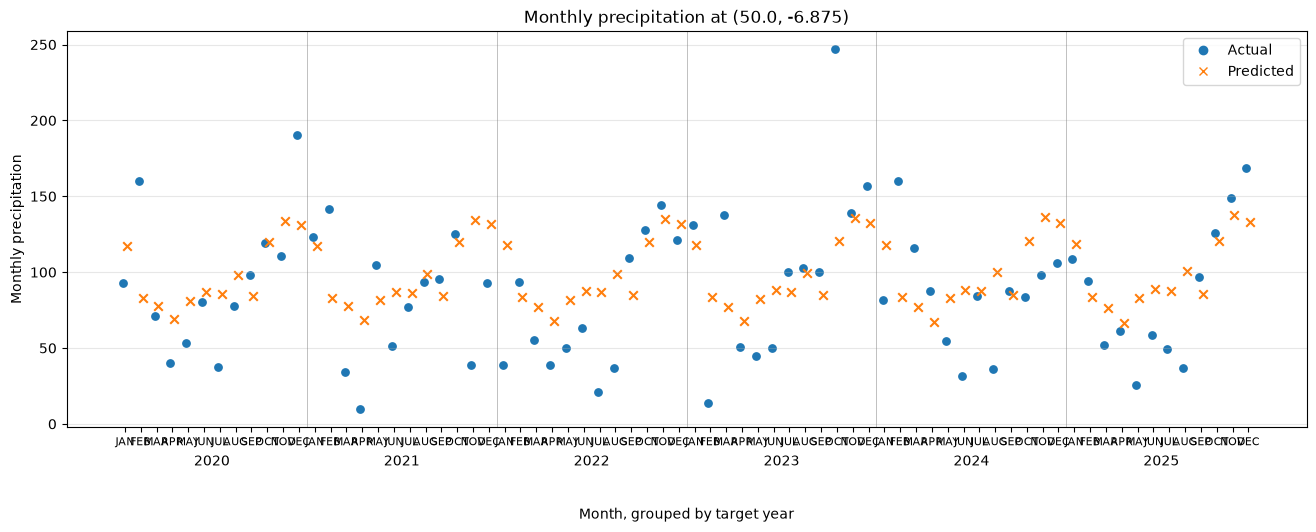

In [ ]:
from matplotlib.lines import Line2D

lat, lon = locations.iloc[0]
site = test[
    np.isclose(test["LAT"], lat) &
    np.isclose(test["LON"], lon)
].sort_values("target_year")

predictions = model.predict(site[features])

fig, ax = plt.subplots(figsize=(16, 6))
month_positions = []
year_centers = []

for year_index, (_, row) in enumerate(site.iterrows()):
    start = year_index * len(months)
    positions = np.arange(start, start + len(months))
    month_positions.extend(positions)
    year_centers.append(positions.mean())

    actual = row[target_cols].to_numpy(dtype=float)
    predicted = predictions[year_index]

    ax.scatter(positions - 0.12, actual, color="tab:blue", s=28)
    ax.scatter(positions + 0.12, predicted, color="tab:orange",
               marker="x", s=38)

    if year_index > 0:
        ax.axvline(start - 0.5, color="gray", linewidth=0.7, alpha=0.5)

ax.set_xticks(month_positions)
ax.set_xticklabels(months * len(site), fontsize=8)

ax.set_xticks(year_centers, minor=True)
ax.set_xticklabels(
    site["target_year"].astype(int).astype(str),
    minor=True
)
ax.tick_params(axis="x", which="minor", length=0, pad=20)

ax.set_ylabel("Monthly precipitation")
ax.set_xlabel("Month, grouped by target year", labelpad=28)
ax.set_title(f"Monthly precipitation at ({lat}, {lon})")
ax.grid(axis="y", alpha=0.3)

ax.legend(handles=[
    Line2D([], [], color="tab:blue", marker="o", linestyle="None",
           label="Actual"),
    Line2D([], [], color="tab:orange", marker="x", linestyle="None",
           label="Predicted"),
])

fig.subplots_adjust(bottom=0.22)
plt.show()

In [ ]:
lag_features = [f"previous_{month}" for month in months]

for month, feature in zip(months, lag_features):
    df[feature] = df[month]

features = ["YEAR", "LAT", "LON"] + lag_features
target_cols = [f"next_{month}" for month in months]

df = df.dropna(subset=features + target_cols)

train = df[df["target_year"] <= 2019]
test = df[df["target_year"] > 2019]

model.fit(train[features], train[target_cols])

predictions = model.predict(test[features])
print("Test R²:", model.score(test[features], test[target_cols]))

Test R²: -0.04982626912677406


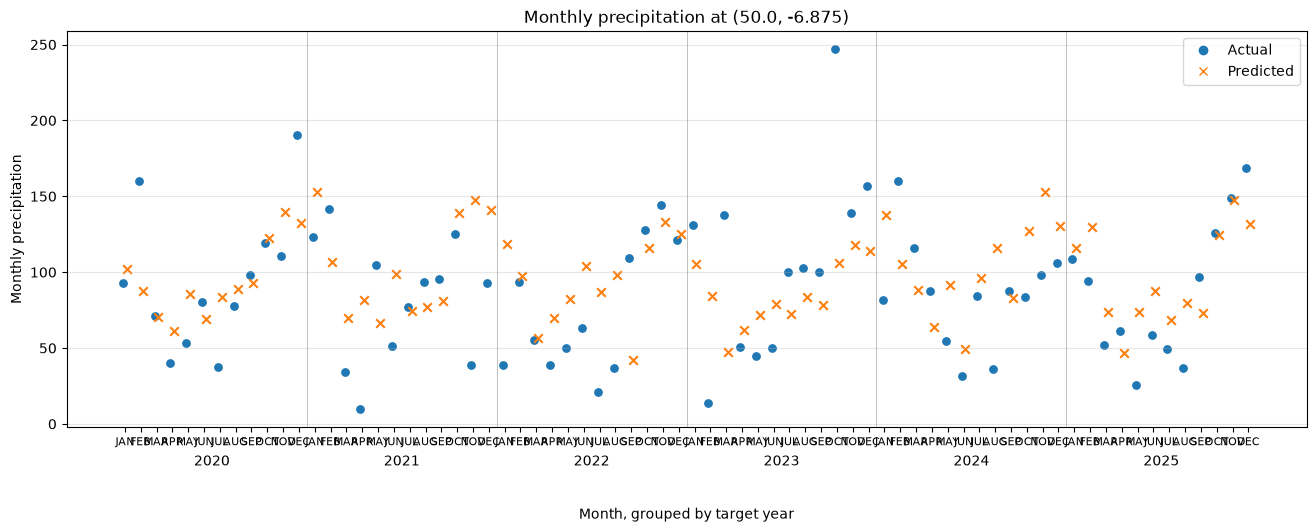

In [ ]:
lat, lon = locations.iloc[0]
site = test[
    np.isclose(test["LAT"], lat) &
    np.isclose(test["LON"], lon)
].sort_values("target_year")

predictions = model.predict(site[features])

fig, ax = plt.subplots(figsize=(16, 6))
month_positions = []
year_centers = []

for year_index, (_, row) in enumerate(site.iterrows()):
    start = year_index * len(months)
    positions = np.arange(start, start + len(months))
    month_positions.extend(positions)
    year_centers.append(positions.mean())

    actual = row[target_cols].to_numpy(dtype=float)
    predicted = predictions[year_index]

    ax.scatter(positions - 0.12, actual, color="tab:blue", s=28)
    ax.scatter(positions + 0.12, predicted, color="tab:orange",
               marker="x", s=38)

    if year_index > 0:
        ax.axvline(start - 0.5, color="gray", linewidth=0.7, alpha=0.5)

ax.set_xticks(month_positions)
ax.set_xticklabels(months * len(site), fontsize=8)

ax.set_xticks(year_centers, minor=True)
ax.set_xticklabels(
    site["target_year"].astype(int).astype(str),
    minor=True
)
ax.tick_params(axis="x", which="minor", length=0, pad=20)

ax.set_ylabel("Monthly precipitation")
ax.set_xlabel("Month, grouped by target year", labelpad=28)
ax.set_title(f"Monthly precipitation at ({lat}, {lon})")
ax.grid(axis="y", alpha=0.3)

ax.legend(handles=[
    Line2D([], [], color="tab:blue", marker="o", linestyle="None",
           label="Actual"),
    Line2D([], [], color="tab:orange", marker="x", linestyle="None",
           label="Predicted"),
])

fig.subplots_adjust(bottom=0.22)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC",
]
lag_features = [f"previous_{month}" for month in months]
target_cols = [f"next_{month}" for month in months]
features = ["YEAR", "LAT", "LON"] + lag_features

df = pd.read_csv("data/POWER_Regional_Monthly_1984_2025.csv", skiprows=9)
df = df[df["ANN"] != -999].copy()
df[months] = df[months].replace(-999, np.nan)
history = df.dropna(subset=months).copy()
history = history.sort_values(["LAT", "LON", "YEAR"])

training_data = history.copy()
by_location = training_data.groupby(["LAT", "LON"])
training_data["target_year"] = by_location["YEAR"].shift(-1)

for month, lag, target in zip(months, lag_features, target_cols):
    training_data[lag] = training_data[month]
    training_data[target] = by_location[month].shift(-1)

training_data = training_data[
    training_data["target_year"] == training_data["YEAR"] + 1
].dropna(subset=features + target_cols)

model = LinearRegression()
model.fit(training_data[features], training_data[target_cols])

latest = history.groupby(["LAT", "LON"]).tail(1)
latest = latest[latest["YEAR"] == 2025]

if latest.empty:
    raise ValueError("No locations have complete observations through 2025.")

forecasts = []
for _, last in latest.iterrows():
    state = {
        "YEAR": int(last["YEAR"]),
        "LAT": last["LAT"],
        "LON": last["LON"],
    }
    for month, lag in zip(months, lag_features):
        state[lag] = last[month]

    for target_year in range(2026, 2031):
        prediction = model.predict(
            pd.DataFrame([state], columns=features)
        )[0]
        prediction = np.maximum(prediction, 0)

        forecasts.append({
            "YEAR": target_year,
            
        state["YEAR"] = target_year
        for month, lag, value in zip(months, lag_features, prediction):
            state[lag] = value

forecast_df = pd.DataFrame(forecasts)
forecast_df = forecast_df.sort_values(["YEAR", "LAT", "LON"]).reset_index(drop=True)
forecast_df.to_csv("data/rainfall_forecast_2026_2030.csv", index=False)
print(forecast_df[:5])

   YEAR   LAT    LON         JAN        FEB        MAR        APR        MAY  \
0  2026  50.0 -6.875  106.524205  90.453353  70.134529  68.542811  62.035785   
1  2026  50.0 -6.250  102.915483  84.472694  67.959547  66.448284  59.983022   
2  2026  50.0 -5.625  101.848987  79.524213  66.581826  65.117427  59.749059   
3  2026  50.0 -5.000   97.123961  69.319070  64.323400  65.191833  57.676017   
4  2026  50.0 -4.375   91.060975  64.992820  62.072889  64.360405  54.014131   

         JUN        JUL        AUG        SEP         OCT         NOV  \
0  61.984414  61.050505  85.061759  92.125479  130.862805  122.121801   
1  61.720953  56.889330  79.858339  92.093388  128.284122  119.531870   
2  62.440230  53.560798  75.396484  94.445358  127.449070  120.126817   
3  64.280050  49.710833  76.842525  96.868062  126.321803  120.419983   
4  61.249105  44.913115  80.257683  95.642982  118.753176  123.315805   

          DEC  
0  140.252247  
1  138.154538  
2  141.403565  
3  140.563500  


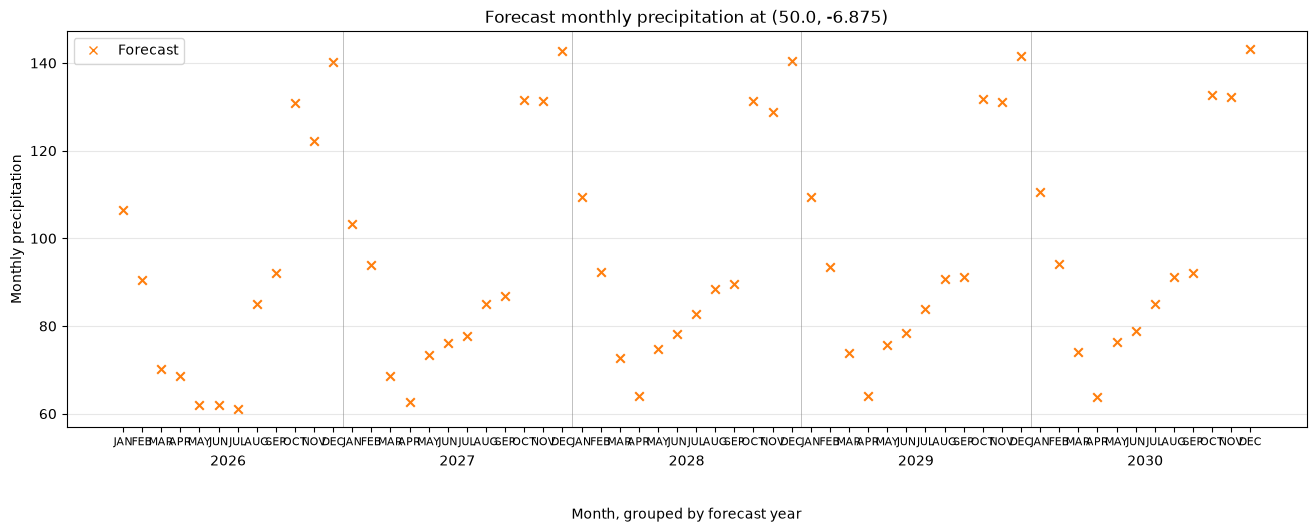

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

forecast_plot_df = pd.read_csv("data/rainfall_forecast_2026_2030.csv")

months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC",
]

forecast_locations = (
    forecast_plot_df[["LAT", "LON"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
if forecast_locations.empty:
    raise ValueError("The forecast CSV contains no locations to plot.")

location_index = 0
lat, lon = forecast_locations.iloc[location_index]
site = forecast_plot_df[
    np.isclose(forecast_plot_df["LAT"], lat)
    & np.isclose(forecast_plot_df["LON"], lon)
].sort_values("YEAR")

fig, ax = plt.subplots(figsize=(16, 6))
month_positions = []
year_centers = []

for year_index, (_, row) in enumerate(site.iterrows()):
    start = year_index * len(months)
    positions = np.arange(start, start + len(months))
    month_positions.extend(positions)
    year_centers.append(positions.mean())

    rainfall = row[months].to_numpy(dtype=float)
    ax.scatter(
        positions,
        rainfall,
        color="tab:orange",
        marker="x",
        s=38,
    )

    if year_index > 0:
        ax.axvline(start - 0.5, color="gray", linewidth=0.7, alpha=0.5)

ax.set_xticks(month_positions)
ax.set_xticklabels(months * len(site), fontsize=8)
ax.set_xticks(year_centers, minor=True)
ax.set_xticklabels(site["YEAR"].astype(int).astype(str), minor=True)
ax.tick_params(axis="x", which="minor", length=0, pad=20)

ax.set_ylabel("Monthly precipitation")
ax.set_xlabel("Month, grouped by forecast year", labelpad=28)
ax.set_title(f"Forecast monthly precipitation at ({lat}, {lon})")
ax.grid(axis="y", alpha=0.3)
ax.legend(handles=[
    Line2D([], [], color="tab:orange", marker="x", linestyle="None",
           label="Forecast"),
])

fig.subplots_adjust(bottom=0.22)
plt.show()
